In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

plt.style.use("seaborn-v0_8-whitegrid")
sns.set_palette("deep")

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
df = pd.read_csv("risk.csv")

print("Dataset Shape:", df.shape)

display(df.head())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all").T)

Dataset Shape: (280660, 16)


,menopaus,agegrp,density,race,Hispanic,bmi,agefirst,nrelbc,brstproc,lastmamm,surgmeno,hrt,invasive,cancer,training,count
0,0,1,1,1,0,1,0,0,0,0,9,9,0,0,1,4
1,0,1,1,1,0,1,0,0,0,9,9,9,0,0,0,2
2,0,1,1,1,0,1,0,0,0,9,9,9,0,0,1,4
3,0,1,1,1,0,1,0,0,1,9,9,9,0,0,1,1
4,0,1,1,1,0,1,0,1,0,0,9,9,0,0,1,1



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 280660 entries, 0 to 280659
Data columns (total 16 columns):
 #   Column    Non-Null Count   Dtype
---  ------    --------------   -----
 0   menopaus  280660 non-null  int64
 1   agegrp    280660 non-null  int64
 2   density   280660 non-null  int64
 3   race      280660 non-null  int64
 4   Hispanic  280660 non-null  int64
 5   bmi       280660 non-null  int64
 6   agefirst  280660 non-null  int64
 7   nrelbc    280660 non-null  int64
 8   brstproc  280660 non-null  int64
 9   lastmamm  280660 non-null  int64
 10  surgmeno  280660 non-null  int64
 11  hrt       280660 non-null  int64
 12  invasive  280660 non-null  int64
 13  cancer    280660 non-null  int64
 14  training  280660 non-null  int64
 15  count     280660 non-null  int64
dtypes: int64(16)
memory usage: 34.3 MB

Statistical Summary:


,count,mean,std,min,25%,50%,75%,max
menopaus,280660.0,1.307130,1.905270,0.0,1.0,1.0,1.0,9.0
agegrp,280660.0,5.471770,2.386063,1.0,4.0,5.0,7.0,10.0
density,280660.0,4.092393,2.958627,1.0,2.0,3.0,9.0,9.0
race,280660.0,3.172365,3.144942,1.0,1.0,1.0,5.0,9.0
Hispanic,280660.0,2.884244,4.060625,0.0,0.0,0.0,9.0,9.0
bmi,280660.0,4.771660,3.469854,1.0,2.0,3.0,9.0,9.0
agefirst,280660.0,3.371239,3.972928,0.0,0.0,1.0,9.0,9.0
nrelbc,280660.0,1.571906,3.057802,0.0,0.0,0.0,1.0,9.0
brstproc,280660.0,1.445881,2.936195,0.0,0.0,0.0,1.0,9.0
lastmamm,280660.0,3.036272,4.197132,0.0,0.0,0.0,9.0,9.0


In [3]:
LABELS = {
    "menopaus": {
        0: "Pre-menopausal",
        1: "Post-menopausal / age >=55",
        9: "Unknown"
    },

    "agegrp": {
        1: "35-39", 2: "40-44", 3: "45-49",
        4: "50-54", 5: "55-59", 6: "60-64",
        7: "65-69", 8: "70-74", 9: "75-79",
        10: "80-84"
    },

    "density": {
        1: "Fatty",
        2: "Scattered",
        3: "Heterogeneously dense",
        4: "Extremely dense",
        9: "Unknown"
    },

    "race": {
        1: "White",
        2: "Asian / Pacific Islander",
        3: "Black",
        4: "Native American",
        5: "Other / Mixed",
        9: "Unknown"
    },

    "Hispanic": {
        0: "No",
        1: "Yes",
        9: "Unknown"
    },

    "bmi": {
        1: "10-24.99",
        2: "25-29.99",
        3: "30-34.99",
        4: ">=35",
        9: "Unknown"
    },

    "agefirst": {
        0: "<30",
        1: ">=30",
        2: "Nulliparous",
        9: "Unknown"
    },

    "nrelbc": {
        0: "0",
        1: "1",
        2: "2+",
        9: "Unknown"
    },

    "brstproc": {
        0: "No",
        1: "Yes",
        9: "Unknown"
    },

    "lastmamm": {
        0: "Negative",
        1: "False positive",
        9: "Unknown"
    },

    "surgmeno": {
        0: "Natural",
        1: "Surgical",
        9: "Unknown / N.A."
    },

    "hrt": {
        0: "No",
        1: "Yes",
        9: "Unknown / N.A."
    }
}

FEATURES = list(LABELS.keys())

BLUE = "#3b6fb6"
RED = "#c0392b"
GREY = "#9aa0a6"

In [4]:
def weighted_summary(df, column):

    temp = df.copy()

    temp["cases"] = temp["cancer"] * temp["count"]

    result = temp.groupby(column).agg(
        exams=("count", "sum"),
        cases=("cases", "sum")
    )

    result["share"] = (
        result["exams"] / result["exams"].sum()
    ) * 100

    result["cancer_rate"] = (
        result["cases"] / result["exams"]
    ) * 100

    return result


def wilson_ci(k, n, z=1.96):

    n = np.asarray(n, dtype=float)
    k = np.asarray(k, dtype=float)

    p = k / n

    den = 1 + z**2 / n

    center = (
        p + z**2 / (2 * n)
    ) / den

    half = z * np.sqrt(
        p * (1 - p) / n +
        z**2 / (4 * n**2)
    ) / den

    return center - half, center + half


overall_cancer_rate = (
    (df["cancer"] * df["count"]).sum()
    / df["count"].sum()
) * 100

print(f"Overall Cancer Rate: {overall_cancer_rate:.3f}%")

Overall Cancer Rate: 0.486%



Analysis: agegrp


,exams,cases,share,cancer_rate
agegrp,,,,
1,42758,88,1.786796,0.205809
2,287281,648,12.005066,0.225563
3,387246,1281,16.182462,0.330797
4,428312,1704,17.898552,0.397841
5,334132,1795,13.962903,0.537213
6,263521,1576,11.012170,0.598055
7,231904,1467,9.690940,0.632589
8,203106,1420,8.487512,0.699142
9,145102,1089,6.063607,0.750507


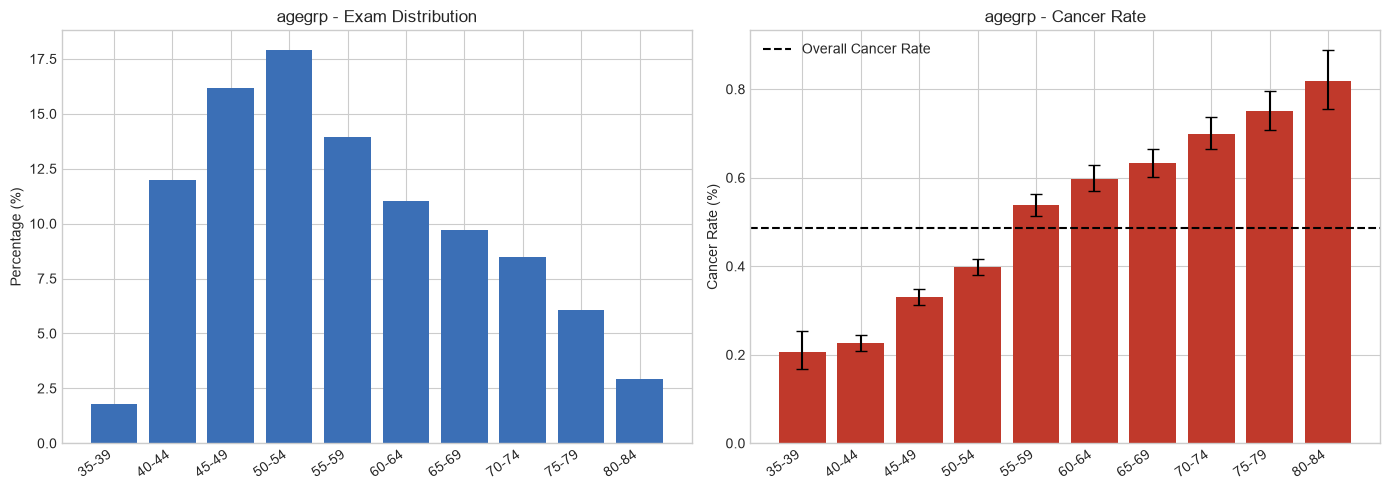


Analysis: race


,exams,cases,share,cancer_rate
race,,,,
1,1738015,8698,72.629187,0.500456
2,102998,425,4.304141,0.412629
3,121534,576,5.078734,0.473941
4,28359,82,1.185082,0.289150
5,22288,102,0.931384,0.457645
9,379804,1755,15.871472,0.462080


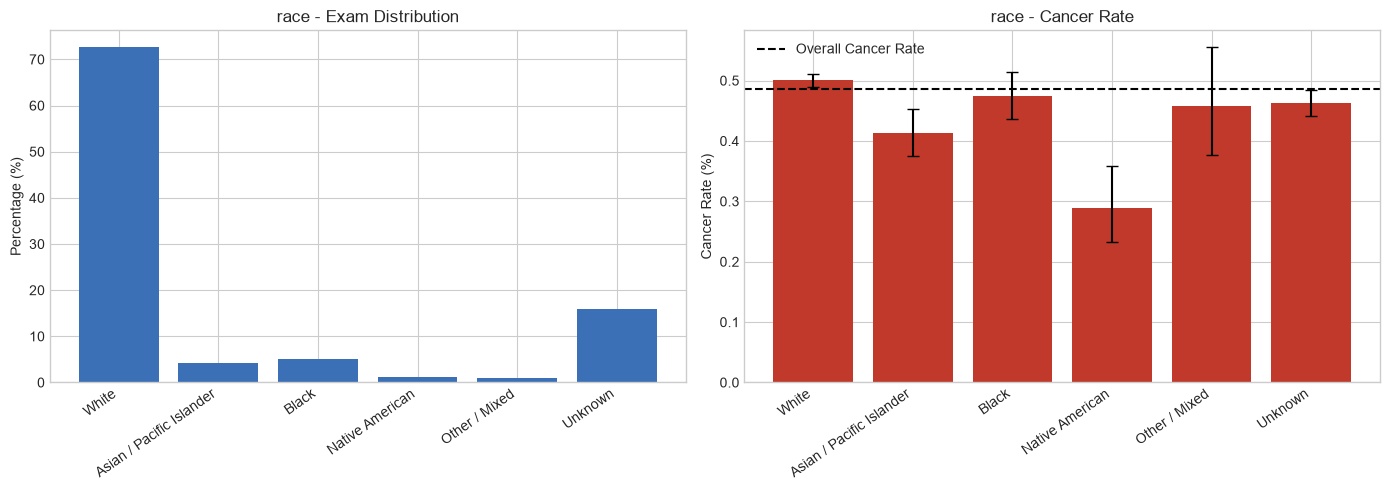


Analysis: Hispanic


,exams,cases,share,cancer_rate
Hispanic,,,,
0,1749604,8772,73.113475,0.501371
1,157340,584,6.575016,0.371171
9,486054,2282,20.311509,0.469495


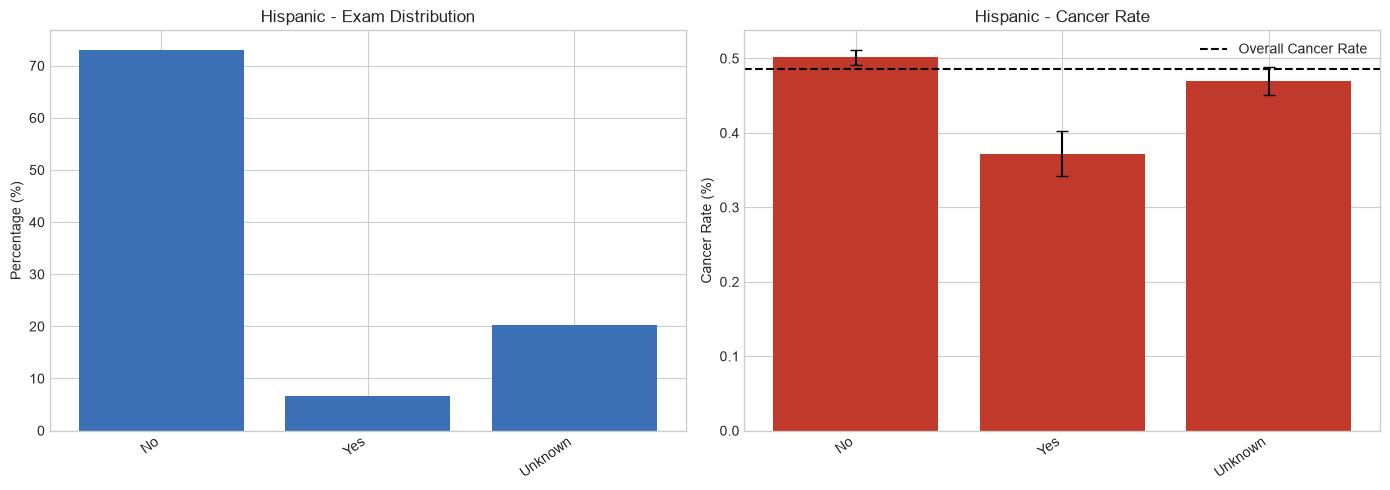


Analysis: bmi


,exams,cases,share,cancer_rate
bmi,,,,
1,508897,2474,21.266085,0.486149
2,325352,1703,13.596000,0.523433
3,144823,754,6.051948,0.520636
4,77821,400,3.252029,0.514000
9,1336105,6307,55.833937,0.472044


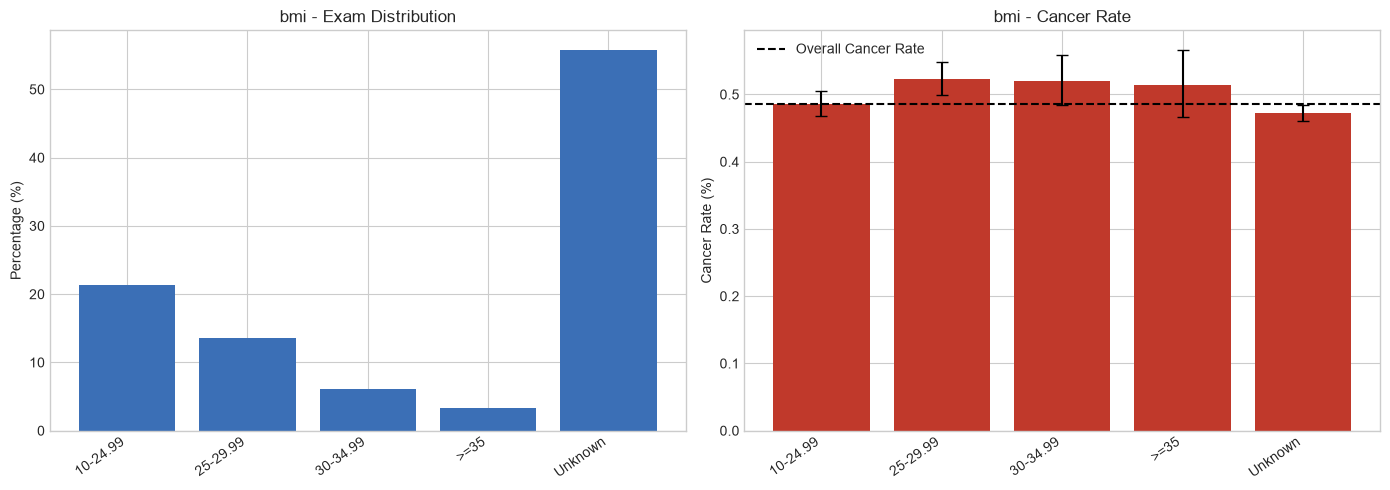

In [5]:
demographic_features = [
    "agegrp",
    "race",
    "Hispanic",
    "bmi"
]

for col in demographic_features:

    print(f"\n{'='*60}")
    print(f"Analysis: {col}")
    print(f"{'='*60}")

    summary = weighted_summary(df, col)

    display(summary)

    labels = [
        LABELS[col][x]
        for x in summary.index
    ]

    x = np.arange(len(summary))

    lo, hi = wilson_ci(
        summary["cases"],
        summary["exams"]
    )

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    # Distribution
    axes[0].bar(
        x,
        summary["share"],
        color=BLUE
    )

    axes[0].set_title(f"{col} - Exam Distribution")
    axes[0].set_ylabel("Percentage (%)")

    # Cancer Rate
    axes[1].bar(
        x,
        summary["cancer_rate"],
        yerr=[
            summary["cancer_rate"] - lo * 100,
            hi * 100 - summary["cancer_rate"]
        ],
        capsize=4,
        color=RED
    )

    axes[1].axhline(
        overall_cancer_rate,
        color="black",
        linestyle="--",
        label="Overall Cancer Rate"
    )

    axes[1].set_title(f"{col} - Cancer Rate")
    axes[1].set_ylabel("Cancer Rate (%)")
    axes[1].legend()

    for ax in axes:
        ax.set_xticks(x)
        ax.set_xticklabels(
            labels,
            rotation=35,
            ha="right"
        )

    plt.tight_layout()
    plt.show()

,exams,cases,share,cancer_rate
density,,,,
1,148209,328,6.193444,0.221309
2,782384,3361,32.694720,0.429584
3,674008,3726,28.165841,0.552812
4,136011,717,5.683707,0.527163
9,652386,3506,27.262288,0.537412


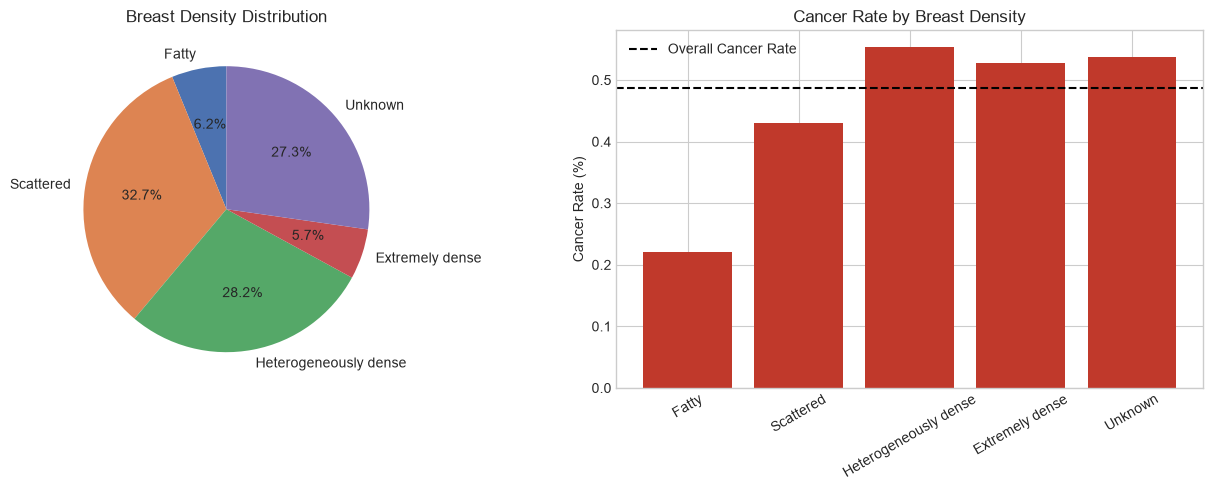

In [7]:
col = "density"

summary = weighted_summary(df, col)

display(summary)

labels = [
    LABELS[col][x]
    for x in summary.index
]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Distribution
axes[0].pie(
    summary["exams"],
    labels=labels,
    autopct="%1.1f%%",
    startangle=90
)

axes[0].set_title("Breast Density Distribution")

# Cancer Rate
axes[1].bar(
    labels,
    summary["cancer_rate"],
    color=RED
)

axes[1].axhline(
    overall_cancer_rate,
    color="black",
    linestyle="--",
    label="Overall Cancer Rate"
)

axes[1].set_title("Cancer Rate by Breast Density")
axes[1].set_ylabel("Cancer Rate (%)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].legend()

plt.tight_layout()
plt.show()

,exams,cases,share,cancer_rate
agefirst,,,,
0,722195,3607,30.179507,0.499450
1,141287,724,5.904184,0.512432
2,201222,1081,8.408783,0.537218
9,1328294,6226,55.507527,0.468722


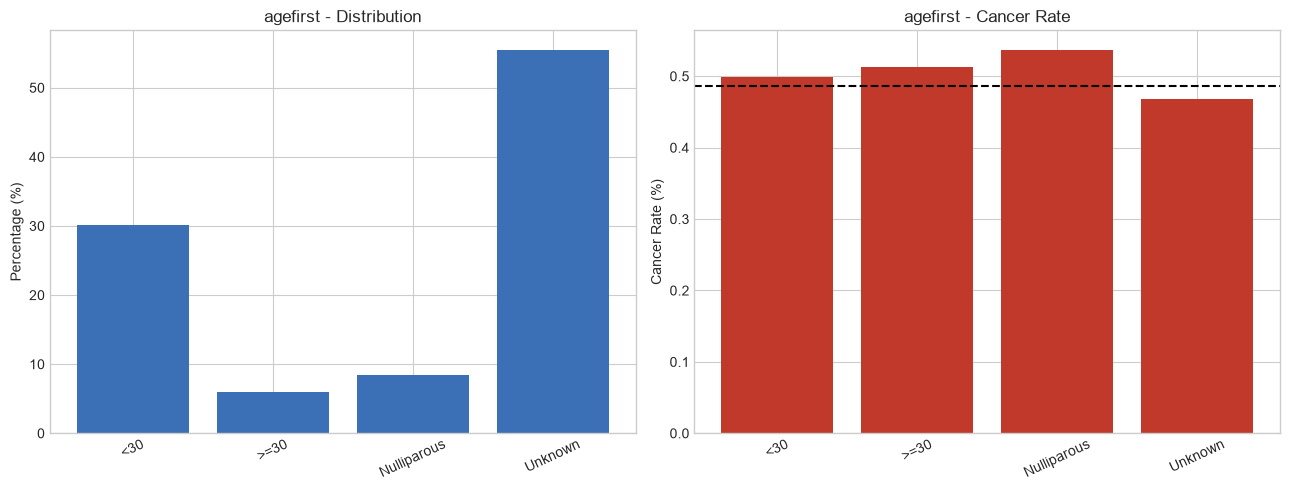

,exams,cases,share,cancer_rate
menopaus,,,,
0,568215,1726,23.744901,0.303758
1,1642824,9300,68.651290,0.566098
9,181959,612,7.603809,0.336340


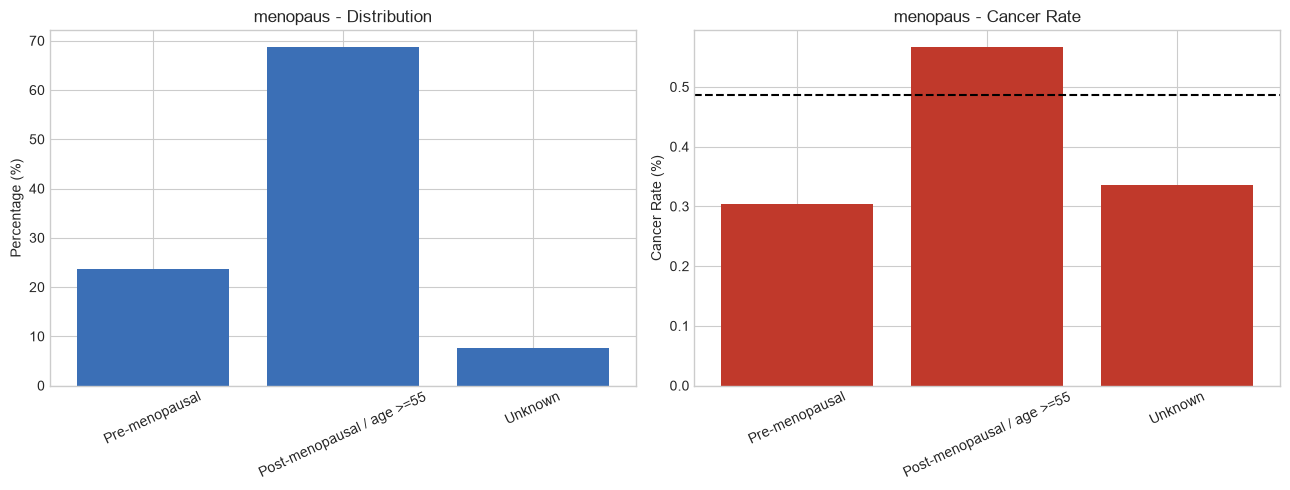

,exams,cases,share,cancer_rate
surgmeno,,,,
0,717966,4316,30.002783,0.601143
1,427332,2180,17.857600,0.510142
9,1247700,5142,52.139617,0.412118


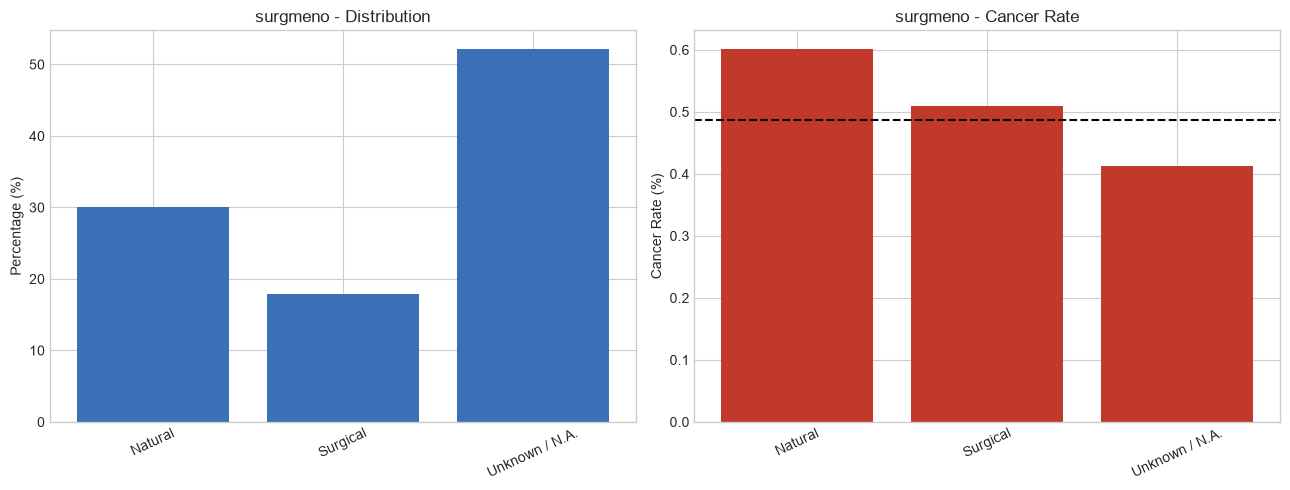

In [8]:
reproductive_features = [
    "agefirst",
    "menopaus",
    "surgmeno"
]

for col in reproductive_features:

    summary = weighted_summary(df, col)

    display(summary)

    labels = [
        LABELS[col][x]
        for x in summary.index
    ]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].bar(
        labels,
        summary["share"],
        color=BLUE
    )

    axes[0].set_title(f"{col} - Distribution")
    axes[0].set_ylabel("Percentage (%)")

    axes[1].bar(
        labels,
        summary["cancer_rate"],
        color=RED
    )

    axes[1].axhline(
        overall_cancer_rate,
        color="black",
        linestyle="--"
    )

    axes[1].set_title(f"{col} - Cancer Rate")
    axes[1].set_ylabel("Cancer Rate (%)")

    for ax in axes:
        ax.tick_params(axis="x", rotation=25)

    plt.tight_layout()
    plt.show()

,exams,cases,share,cancer_rate
nrelbc,,,,
0,1718360,7934,71.807833,0.461719
1,295768,1913,12.359726,0.646791
2,15551,143,0.649854,0.919555
9,363319,1648,15.182587,0.453596


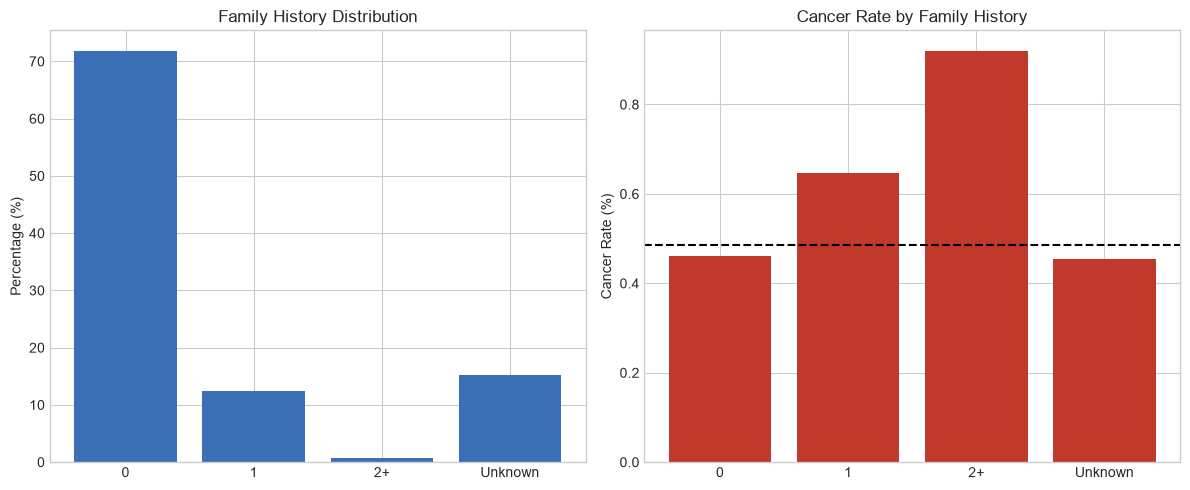

In [9]:
col = "nrelbc"

summary = weighted_summary(df, col)

display(summary)

labels = [
    LABELS[col][x]
    for x in summary.index
]

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].bar(
    labels,
    summary["share"],
    color=BLUE
)

axes[0].set_title("Family History Distribution")
axes[0].set_ylabel("Percentage (%)")

axes[1].bar(
    labels,
    summary["cancer_rate"],
    color=RED
)

axes[1].axhline(
    overall_cancer_rate,
    color="black",
    linestyle="--"
)

axes[1].set_title("Cancer Rate by Family History")
axes[1].set_ylabel("Cancer Rate (%)")

plt.tight_layout()
plt.show()

,exams,cases,share,cancer_rate
brstproc,,,,
0,1722256,7614,71.970641,0.442095
1,420430,2799,17.569175,0.665747
9,250312,1225,10.460184,0.489389


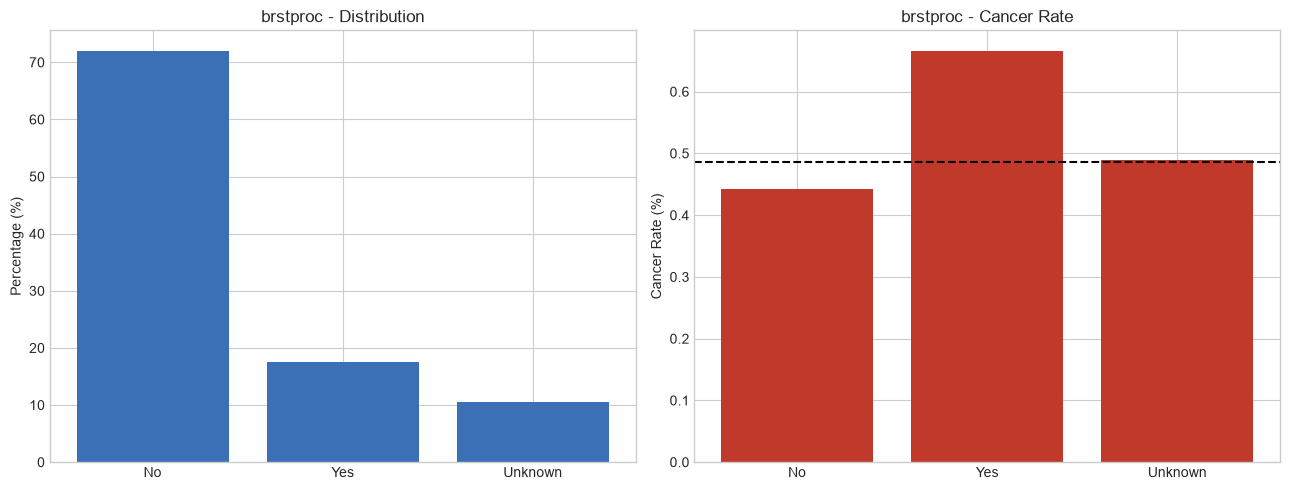

,exams,cases,share,cancer_rate
lastmamm,,,,
0,1799934,8566,75.216695,0.475906
1,34046,267,1.422734,0.784233
9,559018,2805,23.360571,0.501773


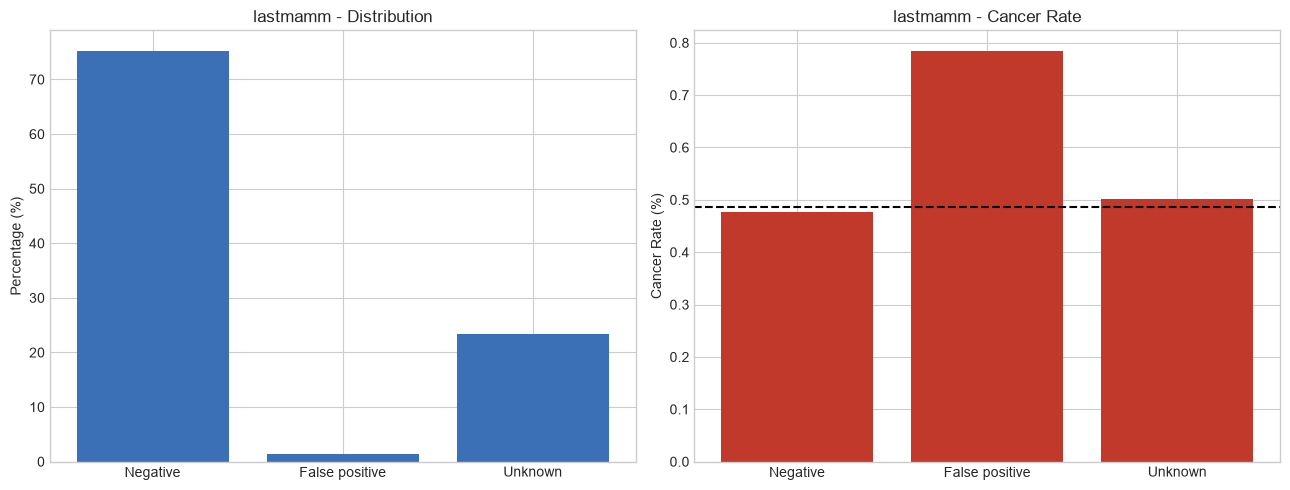

,exams,cases,share,cancer_rate
hrt,,,,
0,729196,3985,30.472069,0.546492
1,683350,3950,28.556229,0.578035
9,980452,3703,40.971702,0.377683


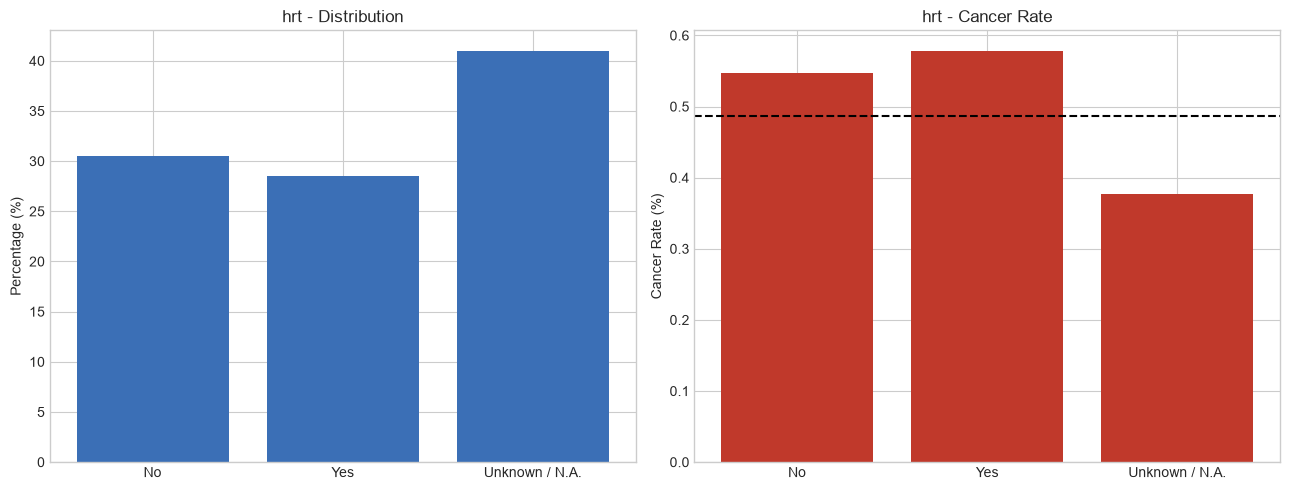

In [10]:
medical_features = [
    "brstproc",
    "lastmamm",
    "hrt"
]

for col in medical_features:

    summary = weighted_summary(df, col)

    display(summary)

    labels = [
        LABELS[col][x]
        for x in summary.index
    ]

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    axes[0].bar(
        labels,
        summary["share"],
        color=BLUE
    )

    axes[0].set_title(f"{col} - Distribution")
    axes[0].set_ylabel("Percentage (%)")

    axes[1].bar(
        labels,
        summary["cancer_rate"],
        color=RED
    )

    axes[1].axhline(
        overall_cancer_rate,
        color="black",
        linestyle="--"
    )

    axes[1].set_title(f"{col} - Cancer Rate")
    axes[1].set_ylabel("Cancer Rate (%)")

    plt.tight_layout()
    plt.show()

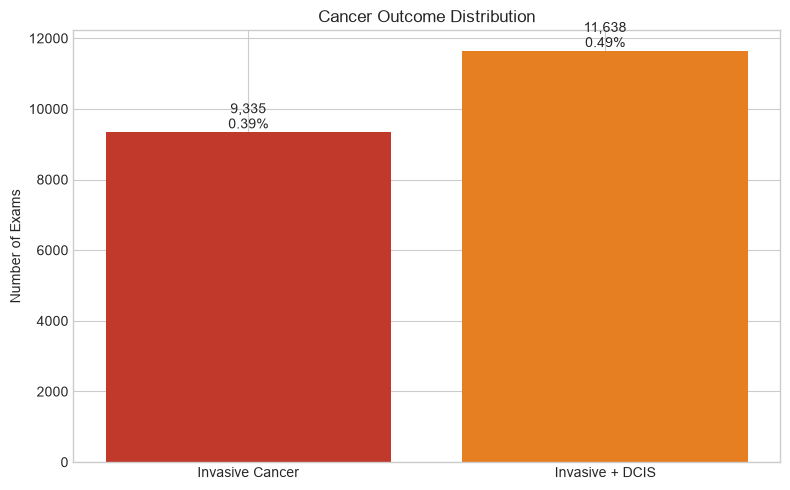

In [11]:
weighted = df["count"]

invasive_cases = (
    df["invasive"] * weighted
).sum()

cancer_cases = (
    df["cancer"] * weighted
).sum()

total_exams = weighted.sum()

labels = [
    "Invasive Cancer",
    "Invasive + DCIS"
]

values = [
    invasive_cases,
    cancer_cases
]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    labels,
    values,
    color=[RED, "#e67e22"]
)

for bar, value in zip(bars, values):

    percentage = value / total_exams * 100

    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{int(value):,}\n{percentage:.2f}%",
        ha="center",
        va="bottom"
    )

ax.set_title("Cancer Outcome Distribution")
ax.set_ylabel("Number of Exams")

plt.tight_layout()
plt.show()

,Feature,Unknown Percentage
1,agegrp,6.063607
0,menopaus,7.603809
8,brstproc,10.460184
7,nrelbc,15.182587
3,race,15.871472
4,Hispanic,20.311509
9,lastmamm,23.360571
2,density,27.262288
11,hrt,40.971702
10,surgmeno,52.139617


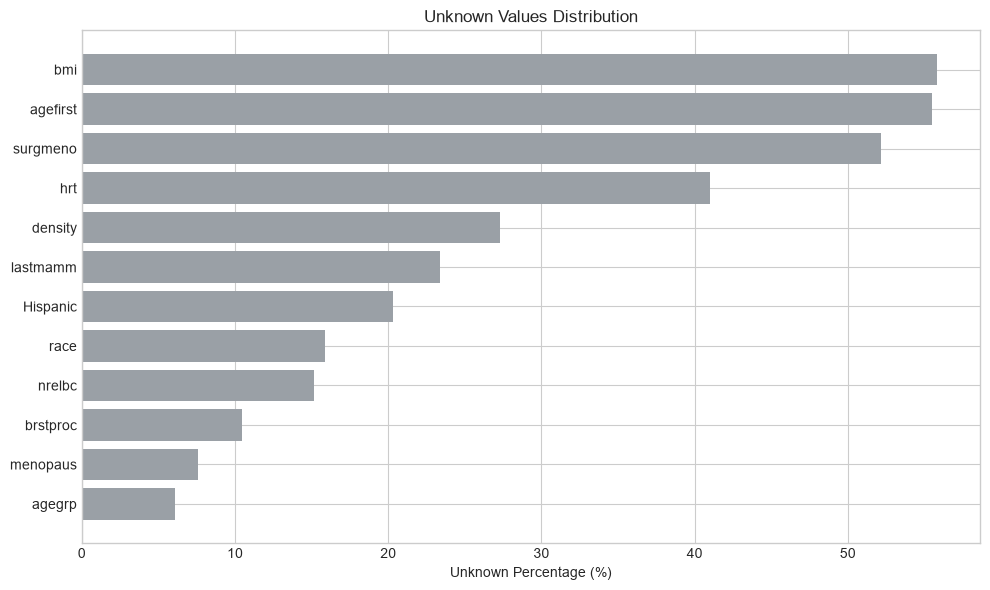

In [12]:
total_exams = df["count"].sum()

unknown_data = {}

for col in FEATURES:

    unknown_exams = df.loc[
        df[col] == 9,
        "count"
    ].sum()

    unknown_data[col] = (
        unknown_exams / total_exams
    ) * 100

unknown_df = pd.DataFrame(
    unknown_data.items(),
    columns=["Feature", "Unknown Percentage"]
)

unknown_df = unknown_df.sort_values(
    "Unknown Percentage"
)

display(unknown_df)

plt.figure(figsize=(10, 6))

plt.barh(
    unknown_df["Feature"],
    unknown_df["Unknown Percentage"],
    color=GREY
)

plt.xlabel("Unknown Percentage (%)")
plt.title("Unknown Values Distribution")

plt.tight_layout()
plt.show()

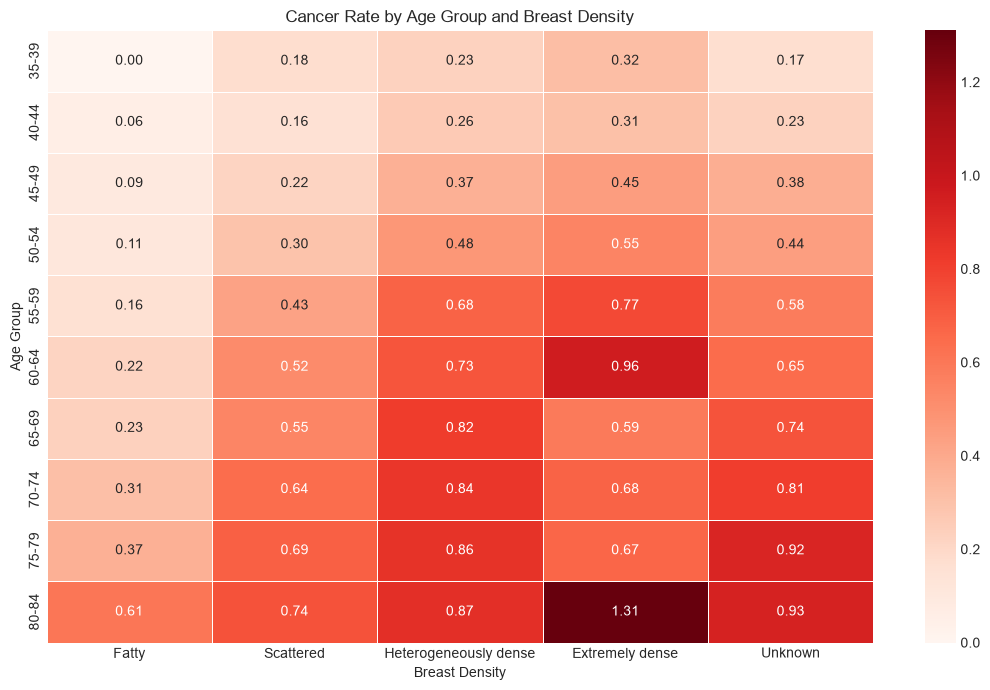

In [13]:
temp = df.copy()

temp["cases"] = (
    temp["cancer"] * temp["count"]
)

pivot = temp.pivot_table(
    index="agegrp",
    columns="density",
    values=["cases", "count"],
    aggfunc="sum"
)

cancer_rate = (
    pivot["cases"] / pivot["count"]
) * 100

cancer_rate.index = [
    LABELS["agegrp"][x]
    for x in cancer_rate.index
]

cancer_rate.columns = [
    LABELS["density"][x]
    for x in cancer_rate.columns
]

plt.figure(figsize=(11, 7))

sns.heatmap(
    cancer_rate,
    annot=True,
    fmt=".2f",
    cmap="Reds",
    linewidths=0.5
)

plt.title("Cancer Rate by Age Group and Breast Density")
plt.xlabel("Breast Density")
plt.ylabel("Age Group")

plt.tight_layout()
plt.show()

,exams,share,cancer_rate
training,,,
0,597859.0,24.983682,0.480214
1,1795139.0,75.016318,0.488374


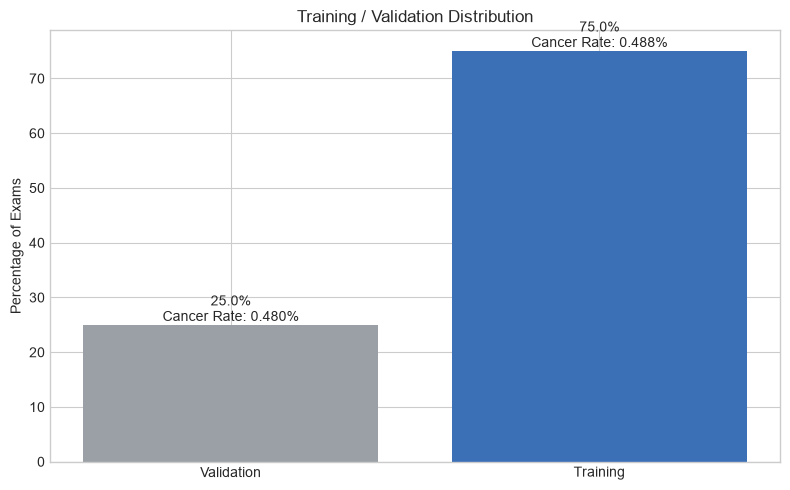

In [14]:
split_summary = df.groupby("training").apply(
    lambda x: pd.Series({

        "exams": x["count"].sum(),

        "share": (
            x["count"].sum() /
            df["count"].sum()
        ) * 100,

        "cancer_rate": (
            (x["cancer"] * x["count"]).sum() /
            x["count"].sum()
        ) * 100
    }),
    include_groups=False
)

display(split_summary)

labels = [
    "Validation",
    "Training"
]

shares = split_summary["share"]

fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    labels,
    shares,
    color=[GREY, BLUE]
)

for bar, (_, row) in zip(bars, split_summary.iterrows()):

    ax.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height(),
        f"{row['share']:.1f}%\nCancer Rate: {row['cancer_rate']:.3f}%",
        ha="center",
        va="bottom"
    )

ax.set_title("Training / Validation Distribution")
ax.set_ylabel("Percentage of Exams")

plt.tight_layout()
plt.show()